#### **A.1 Import Data and Overview**

In [21]:
import tensorflow as tf
from tensorflow.keras.layers import Dropout
from tensorflow.keras import layers, models, optimizers, losses
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc


import os
from PIL import Image
import shutil

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

SEED_VALUE = 1234
np.random.seed(SEED_VALUE)
import random
random.seed(SEED_VALUE)
tf.random.set_seed(SEED_VALUE)

Pada tahap awal untuk menghindari data leakage, saya akan membagi data menjadi train 70%, validation 15%, dan test 15%.

In [2]:
SOURCE_DIR = "data"
OUTPUT_DIR = "2B"
TRAIN_RATIO = 0.7
VAL_RATIO = 0.15

In [3]:
exts = {".jpg", ".jpeg", ".png"}

random.seed(SEED_VALUE)

train_root = os.path.join(OUTPUT_DIR, "train")
val_root = os.path.join(OUTPUT_DIR, "val")
test_root = os.path.join(OUTPUT_DIR, "test")

for split_root in [train_root, val_root, test_root]:
    if os.path.exists(split_root):
        shutil.rmtree(split_root)
    os.makedirs(split_root, exist_ok=True)

for class_name in os.listdir(SOURCE_DIR):
    class_path = os.path.join(SOURCE_DIR, class_name)
    if not os.path.isdir(class_path):
        continue

    files = [
        f for f in os.listdir(class_path)
        if os.path.splitext(f)[1].lower() in exts
    ]

    random.shuffle(files)

    n_total = len(files)
    n_train = int(n_total * TRAIN_RATIO)
    n_val = int(n_total * VAL_RATIO)
    n_test = n_total - n_train - n_val

    train_files = files[:n_train]
    val_files = files[n_train:n_train + n_val]
    test_files = files[n_train + n_val:]

    split_map = {
        "train": (train_root, train_files),
        "val": (val_root, val_files),
        "test": (test_root, test_files),
    }

    for split_name, (split_root, split_files) in split_map.items():
        out_class_dir = os.path.join(split_root, class_name)
        os.makedirs(out_class_dir, exist_ok=True)

        for fname in split_files:
            src = os.path.join(class_path, fname)
            dst = os.path.join(out_class_dir, fname)
            shutil.copy2(src, dst)

    print(f"{class_name}: train={len(train_files)}, val={len(val_files)}, test={len(test_files)}")

Cherry brown_spot: train=429, val=92, test=93
Cherry Leaf Scorch: train=770, val=165, test=166
Cherry Normal leaf: train=350, val=75, test=75
Cherry purple leaf spot: train=690, val=148, test=149
Cherry_shot hole disease: train=308, val=66, test=66


In [4]:
TRAIN_DIR = '2B/train'
VAL_DIR = '2B/val'
TEST_DIR = '2B/test'
DATASET_PATH = TRAIN_DIR

In [5]:
exts = {".jpg", ".jpeg", ".png"}
sizes = {}
for cls in os.listdir(TRAIN_DIR):
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.isdir(cls_path):
        continue
    for fname in os.listdir(cls_path):
        fpath = os.path.join(cls_path, fname)
        if os.path.splitext(fname)[1].lower() in exts:
            try:
                with Image.open(fpath) as im:
                    sizes[(im.width, im.height)] = sizes.get((im.width, im.height), 0) + 1
            except:
                pass
print("Width and height unique sizes and their counts:")
for (w,h), c in sorted(sizes.items(), key=lambda x: (-x[1], x[0])):
    print(f"{(w,h)} -> {c} file")

Width and height unique sizes and their counts:
(800, 1000) -> 2547 file


Sebelum kita mengolah data gambar, kita perlu melihat distribusi Width dan Height pada setiap gambar dalam dataset. Pada dataset ini, semua gambar memiliki size 800x1000 Pixels

In [6]:
class_counts = {}
exts = {".jpg", ".jpeg", ".png"}

for cls in os.listdir(TRAIN_DIR):
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.isdir(cls_path):
        continue
    count = sum(1 for fname in os.listdir(cls_path)
                if os.path.splitext(fname)[1].lower() in exts)
    class_counts[cls] = count

print("Images per class:")
for cls, count in sorted(class_counts.items()):
    print(f"{cls}: {count} images")

print(f"\nTotal images: {sum(class_counts.values())}")

Images per class:
Cherry Leaf Scorch: 770 images
Cherry Normal leaf: 350 images
Cherry brown_spot: 429 images
Cherry purple leaf spot: 690 images
Cherry_shot hole disease: 308 images

Total images: 2547


In [7]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    label_mode='categorical',
    seed=SEED_VALUE,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    VAL_DIR,
    label_mode='categorical',
    seed=SEED_VALUE,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TEST_DIR,
    label_mode='categorical',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False 
)

Found 2547 files belonging to 5 classes.
Found 546 files belonging to 5 classes.
Found 549 files belonging to 5 classes.


Saya melakukan preprocessing dengan mengubah ukuran resolusi dari gambar yang berukuran 800x1000 pixel menjadi 224x224 pixel.

In [8]:
train_ds.class_names

['Cherry Leaf Scorch',
 'Cherry Normal leaf',
 'Cherry brown_spot',
 'Cherry purple leaf spot',
 'Cherry_shot hole disease']

In [9]:
class_names = train_ds.class_names

Jumlah per kelas: {'Cherry brown_spot': 429, 'Cherry Leaf Scorch': 770, 'Cherry Normal leaf': 350, 'Cherry purple leaf spot': 690, 'Cherry_shot hole disease': 308}
Max: 770, Min: 308, Ratio max/min: 2.50


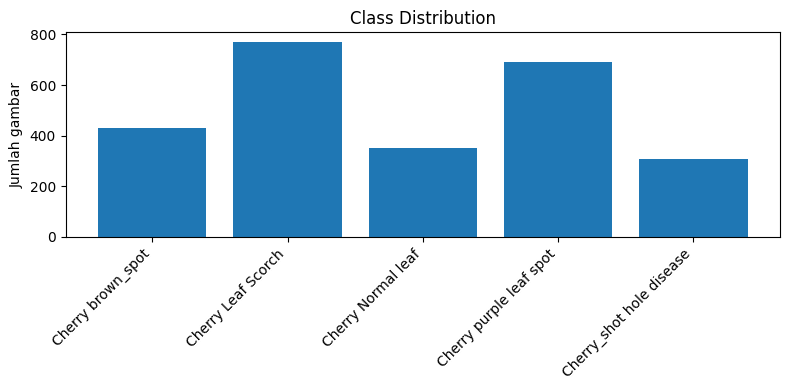

In [11]:
print("Jumlah per kelas:", class_counts)

counts = list(class_counts.values())
max_count = max(counts)
min_count = min(counts)
ratio = max_count / min_count
print(f"Max: {max_count}, Min: {min_count}, Ratio max/min: {ratio:.2f}")
plt.figure(figsize=(8,4))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45, ha='right')
plt.title("Class Distribution")
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.show()

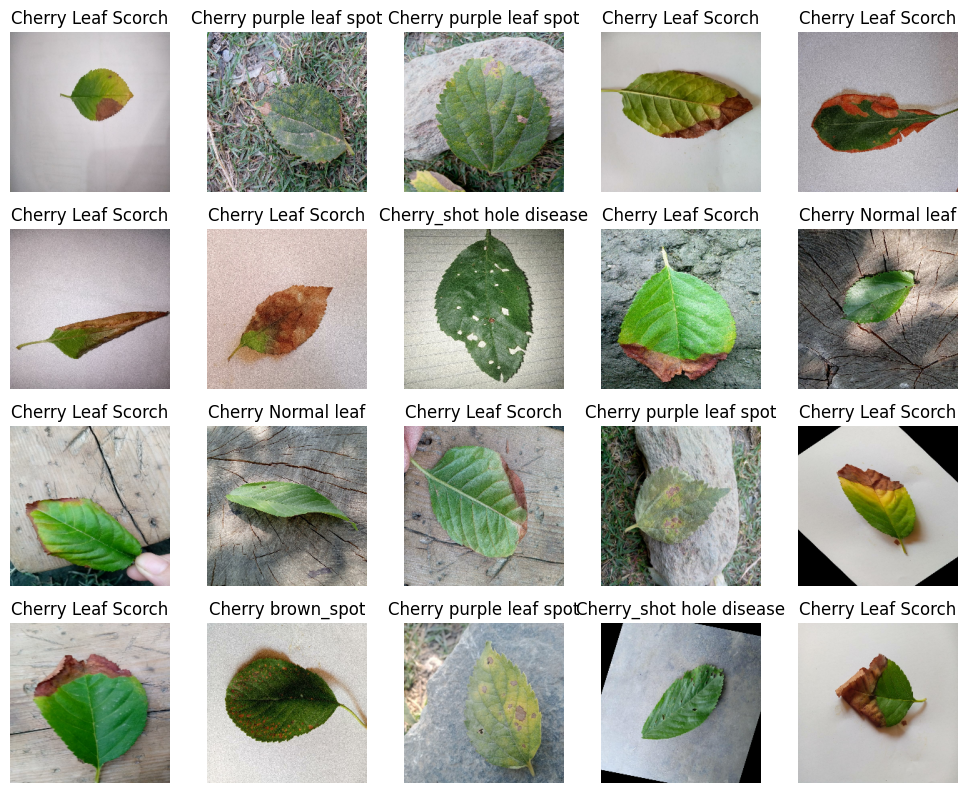

In [10]:
plt.figure(figsize=(10, 10)) 

for images, labels in train_ds.take(1): 
    
    for i in range(20):
        if i >= len(images):
            break
        ax = plt.subplot(5, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        class_index = int(np.argmax(labels[i].numpy()).astype("uint8"))
        plt.title(train_ds.class_names[class_index])
        plt.axis("off")
plt.tight_layout()
plt.show()

Ketika kita melihat beberapa data, nampaknya gambar daun Ceri yang dimiliki dataset telah di manipulasi/edit/augmentasi. Bisa dilihat pada gambar, terdapat beberapa gambar yang terlihat seperti terbalik, ataupun seperti memiliki tumpukan layer pada gambarnya. Dari gambar-gambar di atas juga dapat dilihat bahwa gambar sangat bervariasi, dan memiliki karakteristik yang berbeda.

Findings:
- Terdapat anomali yang nanti harus dihandle dengan baik, yaitu class imbalance.Hal ini dapat menyebabkan model tidak dapat mempelajari kelas kelas dengan tidak merata dan pada akhirnya tidak dapat mengklasifikasikan kelas 'minoritas'.
- Data sudah memiliki ukuran yang tidak square yaitu 800x1000 pixel
- Jumlah dataset mungkin kurang banyak dan memungkin dapat menyebabkan overfitting

#### **A.2 Data Augmentation**

In [ ]:
train_ds = train_ds.cache()

In [13]:
train_ds = train_ds.shuffle(1000)

In [14]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
], name="data_augmentation")

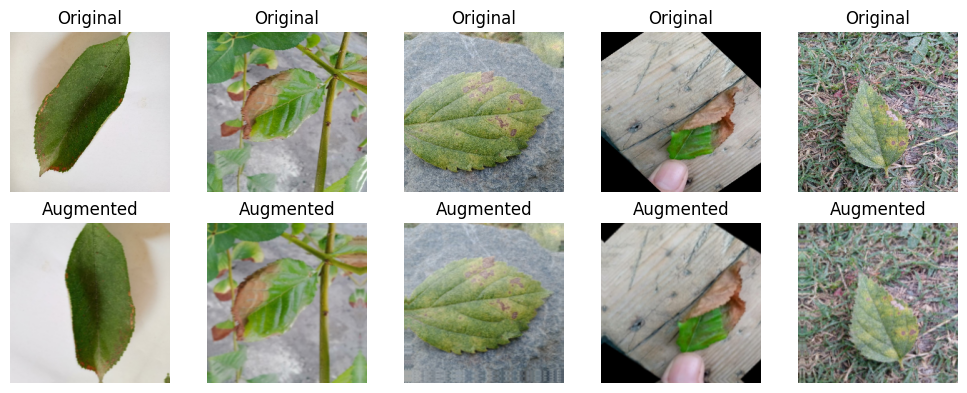

In [15]:
for images, labels in train_ds.take(1):
    sample_images = images[:5]
    augmented_images = data_augmentation(sample_images, training=True)
    break

# Tampilkan sebelum dan sesudah augmentasi
plt.figure(figsize=(10, 4))
for i in range(5):
    # Gambar asli
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.title("Original")
    plt.axis("off")
    
    # Gambar setelah augmentasi
    plt.subplot(2, 5, i + 6)
    plt.imshow(augmented_images[i].numpy().astype("uint8"))
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

Ini merupakan contoh hasil data train yang di augmentasi

In [16]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

hanya augmentasi data train saja, tidak disarankan untuk mengaugmentasi data validasi

In [17]:
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

In [18]:
def test_model(model, test_data):
    y_true, y_pred = [], []

    for images, labels in test_data:
        probs = model.predict(images, verbose=0)
        preds = np.argmax(probs, axis=1)
        true_labels = np.argmax(labels.numpy(), axis=1)

        y_pred.extend(preds.tolist())
        y_true.extend(true_labels.tolist())
        
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot()
    plt.show()

    return y_pred, y_true

### **B. Buatlah sebuah model CNN dengan arsitektur AlexNet secara manual (tidak menggunakan pre-trained model dari Kerasa tau Pytorch) seperti pada gambar di samping dan adaptasikan output layer pada gambar sesuai dengan dataset anda. Model ini akan disebut sebagai Baseline Model. Lakukan training pada model anda dengan minimal 10 epoch dan analisis hasilnya.**

#### **B.1 Model 1 (AlexNet) Training**

In [22]:
model_1 = Sequential([
    layers.Conv2D(96, (11,11), strides=4, activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((3,3), strides=2),
    layers.Conv2D(256, (5,5), padding='same', activation='relu'),
    layers.MaxPooling2D((3,3), strides=2),
    layers.Conv2D(384, (3,3), padding='same', activation='relu'),
    layers.Conv2D(384, (3,3), padding='same', activation='relu'),
    layers.Conv2D(256, (3,3), padding='same', activation='relu'),
    layers.MaxPooling2D((3,3), strides=2),
    layers.Flatten(),
    layers.Dense(4096, activation='relu'), Dropout(0.5),
    layers.Dense(4096, activation='relu'), Dropout(0.5),
    layers.Dense(5, activation='softmax')
])

c:\Users\Tuf Gaming\buat-coding\env\dl\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC()]
)

In [24]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │        20,485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,767,493 (178.40 MB)

 Trainable params: 46,767,493 (178.40 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history_model1 = model_1.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 20,
    verbose = 1,
)
print("Validation metrics:", model_1.evaluate(val_ds, verbose=0))

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 183s 2s/step - accuracy: 0.4307 - auc: 0.7019 - loss: 2.5273 - val_accuracy: 0.6044 - val_auc: 0.8618 - val_loss: 1.0879
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.6392 - auc: 0.8949 - loss: 0.9113 - val_accuracy: 0.7326 - val_auc: 0.9450 - val_loss: 0.6606
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 183s 2s/step - accuracy: 0.7432 - auc: 0.9457 - loss: 0.6561 - val_accuracy: 0.7473 - val_auc: 0.9455 - val_loss: 0.6870
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.7790 - auc: 0.9573 - loss: 0.5805 - val_accuracy: 0.8095 - val_auc: 0.9709 - val_loss: 0.4753
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.8080 - auc: 0.9637 - loss: 0.5278 - val_accuracy: 0.8608 - val_auc: 0.9828 - val_loss: 0.3705
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - accuracy: 0.8410 - auc: 0.9759 - loss: 0.4258 - val_accuracy: 0.8223 - val_auc: 0.9746 - val_loss: 0.4473
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 193s 2s/

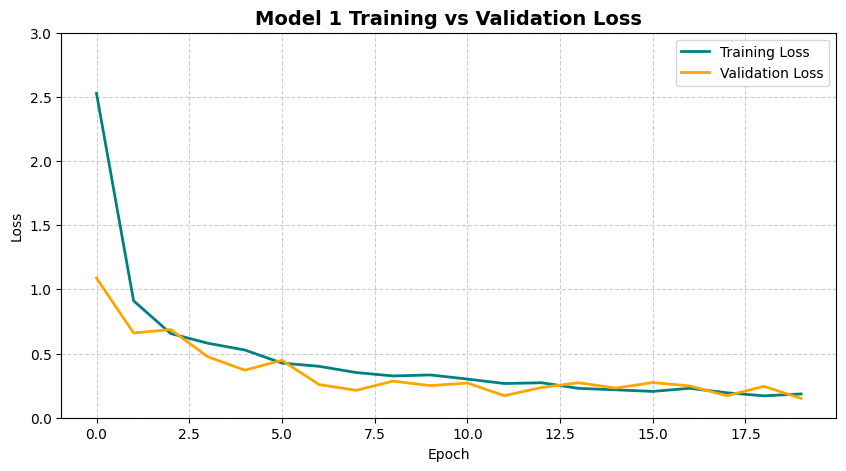

In [26]:
plt.figure(figsize=(10,5))
plt.plot(history_model1.history['loss'], label='Training Loss', color='teal', linewidth=2)
plt.plot(history_model1.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.title('Model 1 Training vs Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim(0, 3.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [27]:
avg_train_loss = np.mean(history_model1.history['loss'])
avg_val_loss = np.mean(history_model1.history['val_loss'])
print(f"Average Training Loss: {avg_train_loss:.4f}")
print(f"Average Validation Loss: {avg_val_loss:.4f}")

Average Training Loss: 0.4656
Average Validation Loss: 0.3503


Dengan menggunakan model pertama, yaitu arsitektur yang diberikan dari soal, model mendapatkan hasil yang sangat baik, dengan training loss 0.46 dan validation loss 0.35. Ketika melihat pada grafik di atas, kita dapat melihat bahwa pada epoch 10 sampai pada epoch 20, model mulai mengalami volataliti yang tidak terlalu besar tetapi masih bisa dianggap baik karena masih di ambang aman, dimana validation loss dan training loss berjlana stabil. Ini menandakan bahwa model mulai cukup baik ketika memroses data validasi dan tidak mengahafal data training. 

### **C. Modifikasi arsitektur AlexNet yang sudah dibuat. Anda bisa menambahkan DropOut, Batch Normalization, dan sebagainya atau melakukan fine-tuning untuk hyperparameter pada model ini. Anda juga bisa mengganti modelnya dengan arsitektur CNN lain seperti DenseNet, EfficientNet, dan sebagainya. Jelaskan alasan modifikasi anda dan lakukan training (minimal 10 epoch), serta analisis hasilnya.**

#### **C.1 Add Class Weight**

In [33]:
class_counts = {}
for class_name in os.listdir(DATASET_PATH):
    class_path = os.path.join(DATASET_PATH, class_name)
    if os.path.isdir(class_path):
        count = len([f for f in os.listdir(class_path) if f.lower().endswith((".jpg",".png",".jpeg"))])
        class_counts[class_name] = count

class_counts

{'Cherry brown_spot': 429,
 'Cherry Leaf Scorch': 770,
 'Cherry Normal leaf': 350,
 'Cherry purple leaf spot': 690,
 'Cherry_shot hole disease': 308}

In [34]:
counts_ordered = [class_counts[name] for name in class_names]
print("Ordered counts:", counts_ordered)

Ordered counts: [770, 350, 429, 690, 308]


In [35]:
counts = np.array(counts_ordered, dtype=np.float64)

base_w = counts.sum() / (len(counts) * counts)

soft_w = np.sqrt(base_w)
soft_w = soft_w / soft_w.mean()
soft_w = np.clip(soft_w, 0.8, 3.0)

class_weights_manual = {i: float(np.round(soft_w[i], 2)) for i in range(len(soft_w))}
print("Updated manual class weights:", class_weights_manual)

for i, cls in enumerate(class_names):
    print(f"{cls}: count={int(counts[i])}, weight={class_weights_manual[i]}")

Updated manual class weights: {0: 0.8, 1: 1.15, 2: 1.04, 3: 0.82, 4: 1.22}
Cherry Leaf Scorch: count=770, weight=0.8
Cherry Normal leaf: count=350, weight=1.15
Cherry brown_spot: count=429, weight=1.04
Cherry purple leaf spot: count=690, weight=0.82
Cherry_shot hole disease: count=308, weight=1.22


Class weight diperbarui berdasarkan distribusi data terbaru pada training set. Bobot dihitung dari inverse-frequency, lalu di-soften (akar kuadrat), dinormalisasi, dan di-clip agar penalty tidak terlalu ekstrem tetapi tetap membantu kelas minoritas.

#### **C.2 Model 2 (AlexNet Weighted) Training**

In [36]:
model_2 = Sequential([
    layers.Conv2D(96, (11,11), strides=4, activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((3,3), strides=(2,2)),
    layers.Conv2D(256, (5,5), padding='same', activation='relu'),
    layers.MaxPooling2D((3,3), strides=(2,2)),
    layers.Conv2D(384, (3,3), padding='same', activation='relu', strides=1),
    layers.Conv2D(384, (3,3), padding='same', activation='relu', strides=1),
    layers.Conv2D(256, (3,3), padding='same', activation='relu', strides=1),
    layers.MaxPooling2D((3,3), strides=(2,2)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(2096, activation='relu'),Dropout(0.2),
    layers.Dense(2096, activation='relu'),Dropout(0.2),
    layers.Dense(5, activation='softmax')
])

c:\Users\Tuf Gaming\buat-coding\env\dl\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Pada Model yang kedua, saya tidak merubah banyak pada arsitekturnya, melainkan saya hanya memodifikasi beberapa hal, seperti strides, menambahkan layer convolution, dan juga menambahkan dropout untuk mencegah overfitting pada model

In [37]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC()]
)

In [38]:
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2096)           │       538,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2096)           │     4,395,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │        10,485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,691,669 (33.16 MB)

 Trainable params: 8,691,669 (33.16 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history_model2 = model_2.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 20,
    class_weight=class_weights_manual,
    verbose = 1,
)

Epoch 1/20


80/80 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.4232 - auc_1: 0.7213 - loss: 1.4675 - val_accuracy: 0.6355 - val_auc_1: 0.8918 - val_loss: 0.9404
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 161s 2s/step - accuracy: 0.6804 - auc_1: 0.9147 - loss: 0.8349 - val_accuracy: 0.7216 - val_auc_1: 0.9398 - val_loss: 0.6906
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.7334 - auc_1: 0.9397 - loss: 0.6986 - val_accuracy: 0.7747 - val_auc_1: 0.9625 - val_loss: 0.5506
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.7845 - auc_1: 0.9620 - loss: 0.5576 - val_accuracy: 0.8278 - val_auc_1: 0.9732 - val_loss: 0.4608
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 167s 2s/step - accuracy: 0.8033 - auc_1: 0.9676 - loss: 0.5073 - val_accuracy: 0.7637 - val_auc_1: 0.9399 - val_loss: 0.8098
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.8398 - auc_1: 0.9761 - loss: 0.4295 - val_accuracy: 0.8223 - val_auc_1: 0.9707 - val_loss: 0.4622
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━

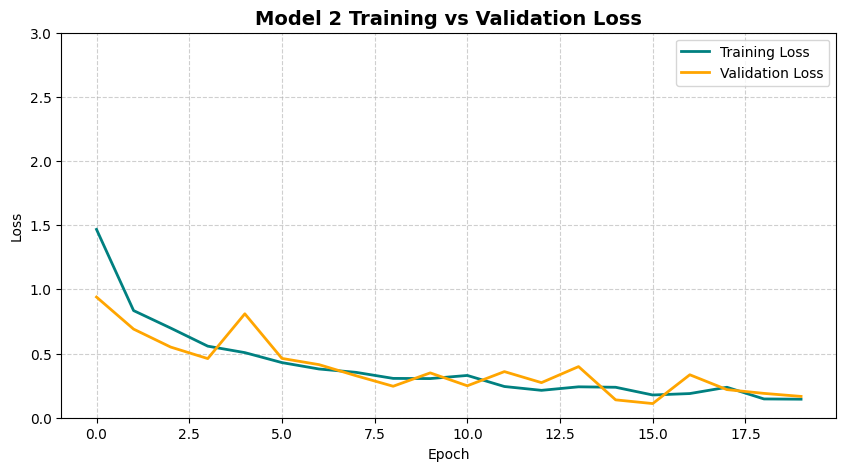

In [40]:
plt.figure(figsize=(10,5))
plt.plot(history_model2.history['loss'], label='Training Loss', color='teal', linewidth=2)
plt.plot(history_model2.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.title('Model 2 Training vs Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim(0, 3.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [41]:
avg_train_loss_model2 = np.mean(history_model2.history['loss'])
avg_val_loss_model2 = np.mean(history_model2.history['val_loss'])
print(f"Average Training Loss: {avg_train_loss_model2:.4f}")
print(f"Average Validation Loss: {avg_val_loss_model2:.4f}")

Average Training Loss: 0.3999
Average Validation Loss: 0.3844


Pada model kedua ini, model memiliki nilai loss yang sedikit lebih kecil dibandingkan dengan model sebelumnya. Dan jika melihat grafik dari training loss dan validation loss, model 2 ini jauh lebih berfluktuasi daripada model pertama. Hal ini dikarenakan model dipaksa untuk belajar dengan weight yang membuat kelas minoritas mendapat peluang yang sama untuk dipelajari dengan kelas mayoritas.

#### **C.3 ResNet50**

In [47]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [49]:
res_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
res_model.trainable = False

Pretrained model yang saya gunakan pada model ketiga ini adalah ResNet50. ResNet50 adalah pretrained model yang dilatih di ImageNet dengan lebih dari 1000 kelas, model pretrained ini memiliki kemampuan yang sangat baik dalam klasifikasi images. Pada model ketiga ini, saya menggabungkan custom cnn dengan base model ResNet50, dengan tujuan menangkap pola yang kompleks dan memberikan model dengan akurasi yang tinggi

In [50]:
resnet_model = Sequential([
    layers.Lambda(preprocess_input, name="resnet_preproc"),
    res_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax"),
], name="resnet50_tl")

In [51]:
resnet_model.build(input_shape=(None, 224, 224, 3))

In [52]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC()]
)

In [53]:
resnet_model.summary()

Model: "resnet50_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet_preproc (Lambda)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,629 (90.98 MB)

 Trainable params: 262,917 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [54]:
resnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5, min_lr=1e-5),
]

In [55]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=resnet_callbacks,
    verbose=1,
    class_weight=class_weights_manual
)

Epoch 1/20


80/80 ━━━━━━━━━━━━━━━━━━━━ 290s 3s/step - accuracy: 0.4656 - auc_2: 0.7590 - loss: 1.3811 - val_accuracy: 0.7949 - val_auc_2: 0.9531 - val_loss: 0.6830 - learning_rate: 1.0000e-04
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 293s 4s/step - accuracy: 0.7004 - auc_2: 0.9157 - loss: 0.8240 - val_accuracy: 0.8663 - val_auc_2: 0.9794 - val_loss: 0.4475 - learning_rate: 1.0000e-04
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 303s 4s/step - accuracy: 0.7754 - auc_2: 0.9523 - loss: 0.6316 - val_accuracy: 0.9048 - val_auc_2: 0.9887 - val_loss: 0.3329 - learning_rate: 1.0000e-04
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 291s 4s/step - accuracy: 0.8229 - auc_2: 0.9692 - loss: 0.5130 - val_accuracy: 0.9194 - val_auc_2: 0.9922 - val_loss: 0.2640 - learning_rate: 1.0000e-04
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 278s 3s/step - accuracy: 0.8461 - auc_2: 0.9754 - loss: 0.4492 - val_accuracy: 0.9322 - val_auc_2: 0.9947 - val_loss: 0.2222 - learning_rate: 1.0000e-04
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 299s 4s/step - acc

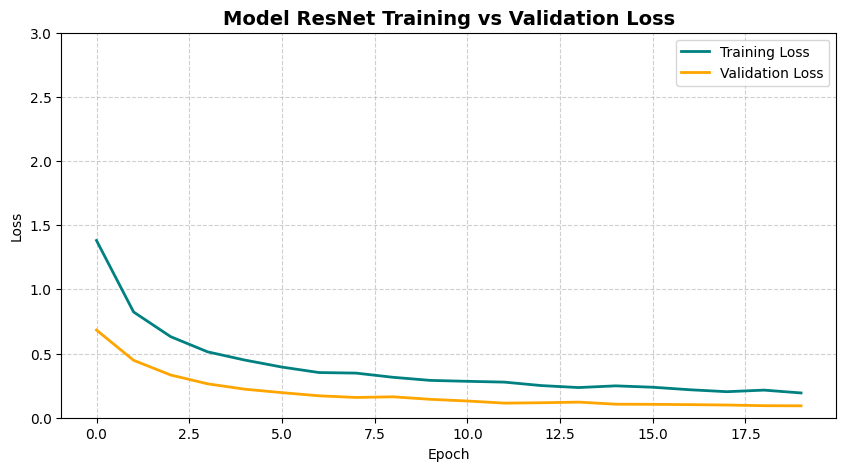

In [56]:
plt.figure(figsize=(10,5))
plt.plot(history_resnet.history['loss'], label='Training Loss', color='teal', linewidth=2)
plt.plot(history_resnet.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.title('Model ResNet Training vs Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim(0, 3.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [57]:
avg_train_loss_resnet = np.mean(history_resnet.history['loss'])
avg_val_loss_resnet = np.mean(history_resnet.history['val_loss'])
print(f"Average Training Loss: {avg_train_loss_resnet:.4f}")
print(f"Average Validation Loss: {avg_val_loss_resnet:.4f}")

Average Training Loss: 0.3930
Average Validation Loss: 0.1930


Dengan menggunakan Transfer Learning, kita dapat melihat bahwa perbedaan yang terjadi sangat signifikan, yaitu loss turun sampai ke angka 0.1. Ini membuktikan bahwa Pretrained Model ResNet dengan CNN sangat efektif dalam melakukan image classification. Penggunaan dropout juga mencegah model untuk overfit. Dengan melihat grafik di atas, dapat dikatakan bahwa loss semakin konvergen, dan model belajar dengan sangat baik. Tidak terjadi overfitting, dan mari kita lihat hasilnya pada data test

### **D. Lakukan evaluasi performa model anda pada data test dengan menggunakan minimal 3 evaluation metrics. Analisis, jelaskan, dan simpulkan hasilnya. Lalu, berikan saran untuk pengembangan lebih lanjut dari model anda**


#### **D.1 Model 1**

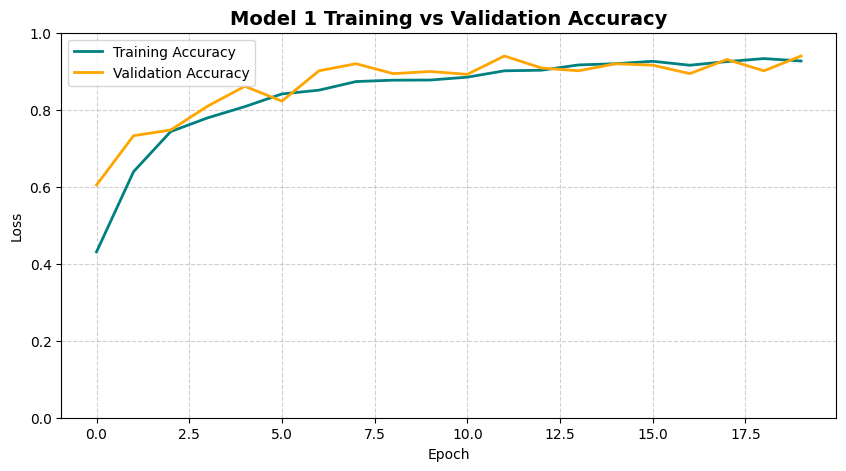

In [28]:
plt.figure(figsize=(10,5))
plt.plot(history_model1.history['accuracy'], label='Training Accuracy', color='teal', linewidth=2)
plt.plot(history_model1.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Model 1 Training vs Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

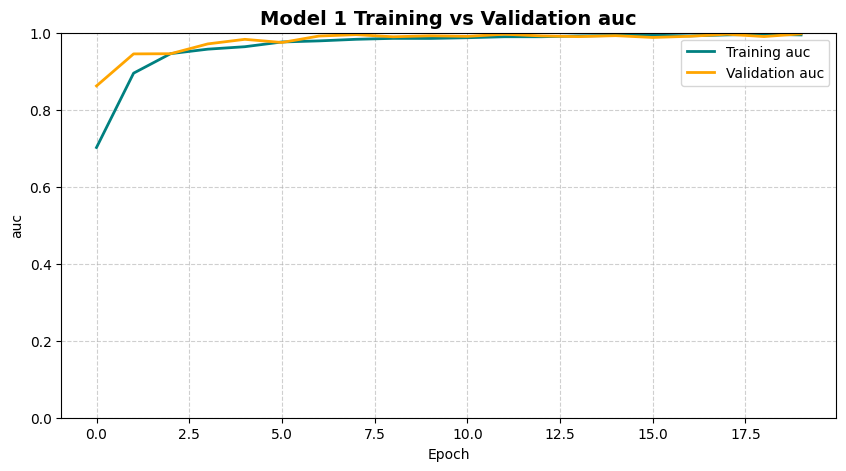

In [29]:
plt.figure(figsize=(10,5))
plt.plot(history_model1.history['auc'], label='Training auc', color='teal', linewidth=2)
plt.plot(history_model1.history['val_auc'], label='Validation auc', color='orange', linewidth=2)
plt.title('Model 1 Training vs Validation auc', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('auc')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

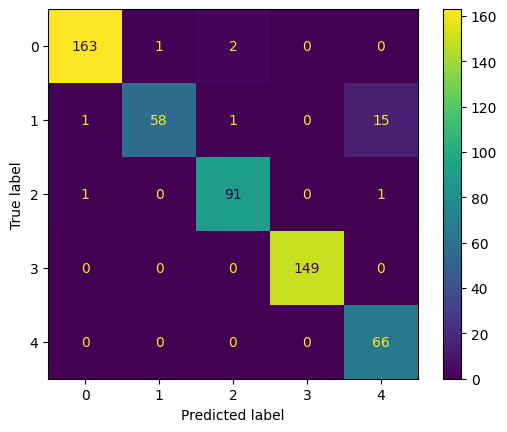

In [30]:
y_pred_model1, y_true = test_model(model_1, test_ds)

In [31]:
print(classification_report(y_true, y_pred_model1, target_names=test_ds.class_names))

                          precision    recall  f1-score   support

      Cherry Leaf Scorch       0.99      0.98      0.98       166
      Cherry Normal leaf       0.98      0.77      0.87        75
       Cherry brown_spot       0.97      0.98      0.97        93
 Cherry purple leaf spot       1.00      1.00      1.00       149
Cherry_shot hole disease       0.80      1.00      0.89        66

                accuracy                           0.96       549
               macro avg       0.95      0.95      0.94       549
            weighted avg       0.97      0.96      0.96       549



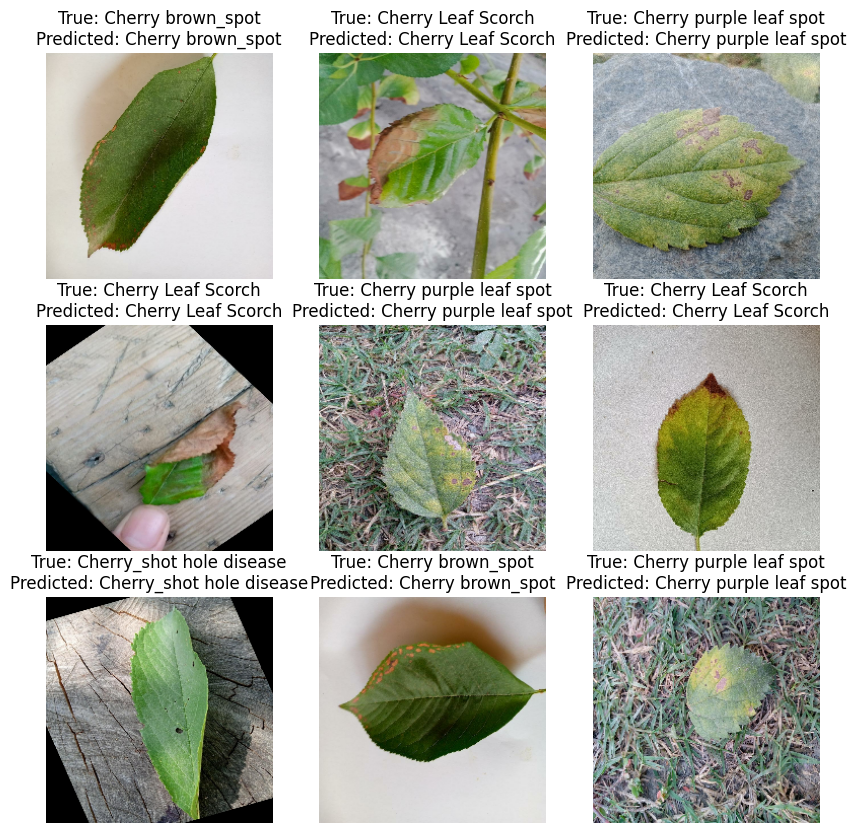

In [32]:
plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    image = images[i].numpy()
    true_label = np.argmax(labels[i].numpy())
    
    probs = model_1.predict(np.expand_dims(image, axis=0), verbose=0)
    pred_class = np.argmax(probs, axis=1)[0]

    plt.imshow(image.astype("uint8"))
    plt.title(f"True: {class_names[true_label]}\nPredicted: {class_names[pred_class]}")
    plt.axis("off")

plt.show()

Berdasarkan metrics yang kita lihat di atas, dapat dilihat bahwa performa dari model 1, seperti yang diharapkan ketika melihat training loss dan val loss nya. Model memberikan hasil prediksi yang cukup baik dan Ketika kita melihat hasil dari confusion matrixnya, kita juga melihat bahwa model juga cukup berani untuk menebak kelas minoritas. Tetapi masih kurang.

Performance
- Accuracy: Accuracy hanyalah metric yang mengukur persentase model benar menebak. ketika training, dapat dilihat bahwa persentase accuracy menurun cukup banyak ketika diuji pada data test. Hal ini menunjukkan overfitting
- Precision: Artinya adalah mengukur keakuratan model ketika memprediksi positif. Contohnya, pada kelas CHerry_brown_spot finger kita mendapatkan precision 0.97, artinya adalah dari semua prediksi positif yang kita buat, 97% nya betul 
- Recall: Recall adalah mengukur seberapa banyak kasus positif yang berhasil diprediksi oleh model. Contohnya pada CHerry_Nrmal_leaf, kita mendapatkan recall yang rendah, yaitu 0.77. Artinya model hanya berhasil menangkap 77% dari semua kasus positif pada label itu.
- F1-Score: F1 score adalah harmonic mean antara precision dan recall, yang biasanya digunakan untuk lebih menggambarkan keseluruhan performance. Contohnya pada purple_leaf_spot mendapatkan F1 score sebesar 1.00, artinya model memiliki keseimbangan yang sangat baik antara precision dan recall
- AUC: AUC mengukur seberapa baik performa model dalam memisahkan kelas positif dan negatif secara menyeluruh. semakin mendekati 1 maka semakin baik.

Analisis
- Model sudah cukup baik dan konvergen, tetapi masih ada kesalahan dalam menebak kelas minoritas b
- Perlu tuning pada model agar achieve hasil lebih baik.
- Kita perlu memperhatikan recall, dimana data kesehatan tumbuhan lebih mengutamakan recall. Karena lebih penting kita bisa menangkap pasien yang benar-benar memiliki penyakit pada daun cherry kita, daripada terlewat.

#### **D.2 Model 2**

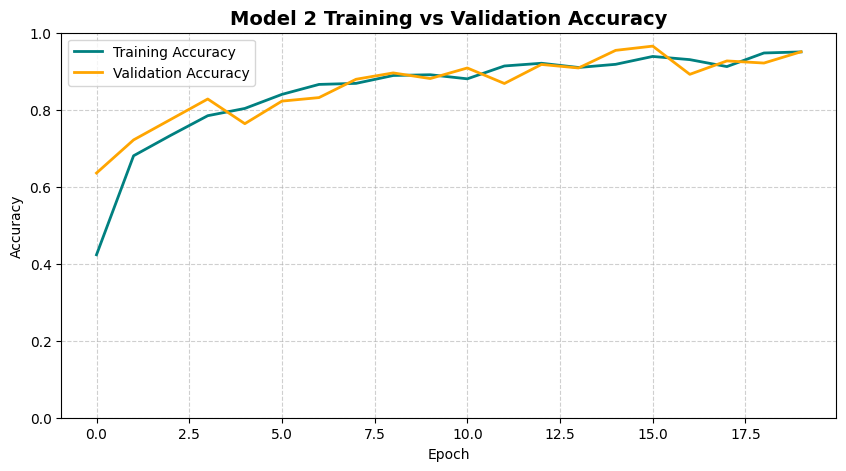

In [42]:
plt.figure(figsize=(10,5))
plt.plot(history_model2.history['accuracy'], label='Training Accuracy', color='teal', linewidth=2)
plt.plot(history_model2.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Model 2 Training vs Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

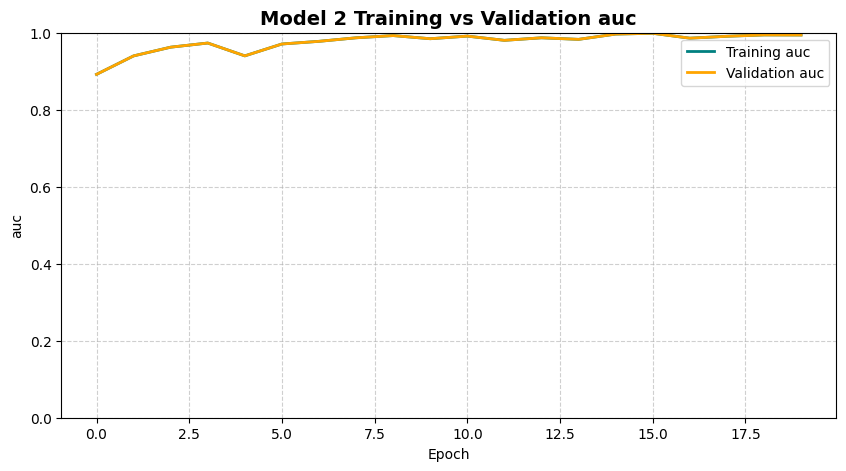

In [58]:
plt.figure(figsize=(10,5))
plt.plot(history_model2.history['val_auc_1'], label='Training auc', color='teal', linewidth=2)
plt.plot(history_model2.history['val_auc_1'], label='Validation auc', color='orange', linewidth=2)
plt.title('Model 2 Training vs Validation auc', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('auc')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

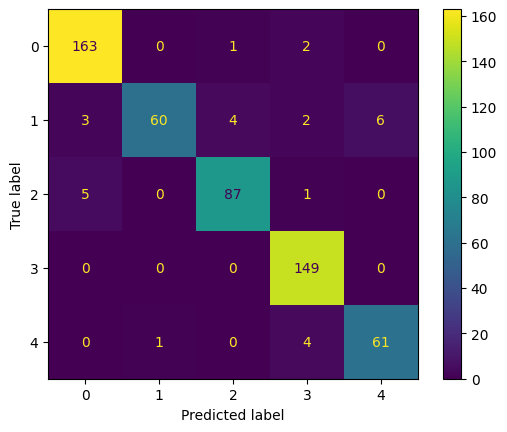

In [44]:
y_pred_model2, y_true = test_model(model_2, test_ds)

In [45]:
print(classification_report(y_true, y_pred_model2, target_names=test_ds.class_names)) 

                          precision    recall  f1-score   support

      Cherry Leaf Scorch       0.95      0.98      0.97       166
      Cherry Normal leaf       0.98      0.80      0.88        75
       Cherry brown_spot       0.95      0.94      0.94        93
 Cherry purple leaf spot       0.94      1.00      0.97       149
Cherry_shot hole disease       0.91      0.92      0.92        66

                accuracy                           0.95       549
               macro avg       0.95      0.93      0.94       549
            weighted avg       0.95      0.95      0.95       549



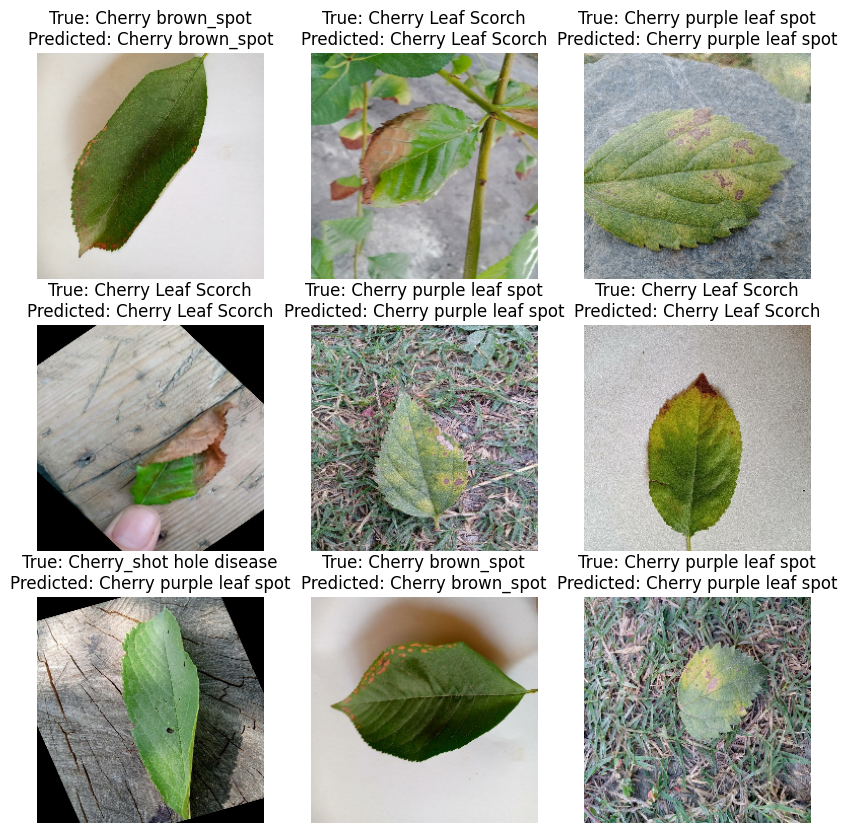

In [46]:
plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    image = images[i].numpy()
    true_label = np.argmax(labels[i].numpy())
    
    probs = model_2.predict(np.expand_dims(image, axis=0), verbose=0)
    pred_class = np.argmax(probs, axis=1)[0]

    plt.imshow(image.astype("uint8"))
    plt.title(f"True: {class_names[true_label]}\nPredicted: {class_names[pred_class]}")
    plt.axis("off")

plt.show()

Berdasarkan model kedua, dapat dilihat bahwa model memiliki peningkatan dari model sebelumnya: dimana model sudah tidak terlalu dominan kepada satu kelas. Berdasarkan analisis saya, model kedua ini lebih robust dan generalize terhadap data baru, dapat dilihat ketika kita uji dengan data yang belum pernah dilihat, model dapat achieve score accuracy yang lebih tinggi dibandingkan saat training dan validating.

#### **D.3 Transfer Learning ResNet50**

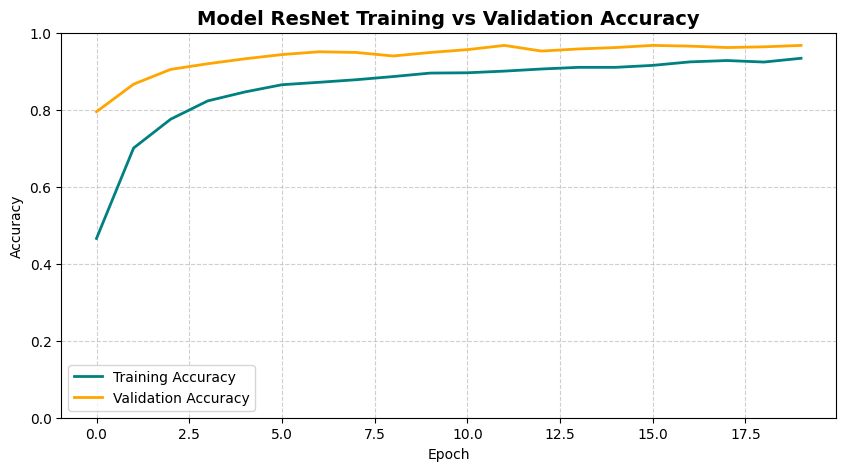

In [59]:
plt.figure(figsize=(10,5))
plt.plot(history_resnet.history['accuracy'], label='Training Accuracy', color='teal', linewidth=2)
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Model ResNet Training vs Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

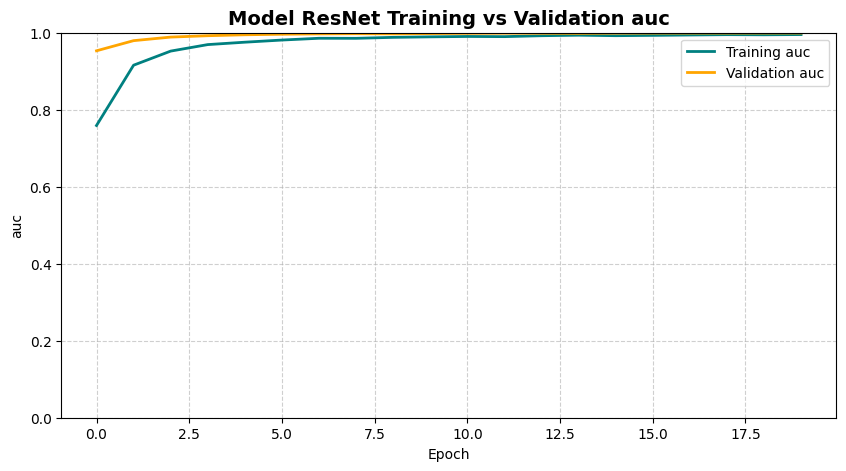

In [60]:
plt.figure(figsize=(10,5))
plt.plot(history_resnet.history['auc_2'], label='Training auc', color='teal', linewidth=2)
plt.plot(history_resnet.history['val_auc_2'], label='Validation auc', color='orange', linewidth=2)
plt.title('Model ResNet Training vs Validation auc', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('auc')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

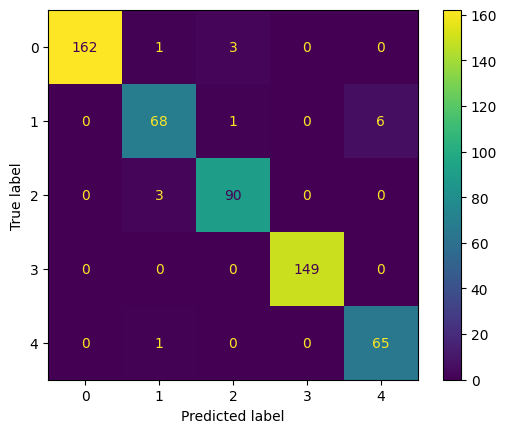

In [61]:
y_pred_resnet, y_true = test_model(resnet_model, test_ds)

In [62]:
print(classification_report(y_true, y_pred_resnet, target_names=test_ds.class_names))

                          precision    recall  f1-score   support

      Cherry Leaf Scorch       1.00      0.98      0.99       166
      Cherry Normal leaf       0.93      0.91      0.92        75
       Cherry brown_spot       0.96      0.97      0.96        93
 Cherry purple leaf spot       1.00      1.00      1.00       149
Cherry_shot hole disease       0.92      0.98      0.95        66

                accuracy                           0.97       549
               macro avg       0.96      0.97      0.96       549
            weighted avg       0.97      0.97      0.97       549



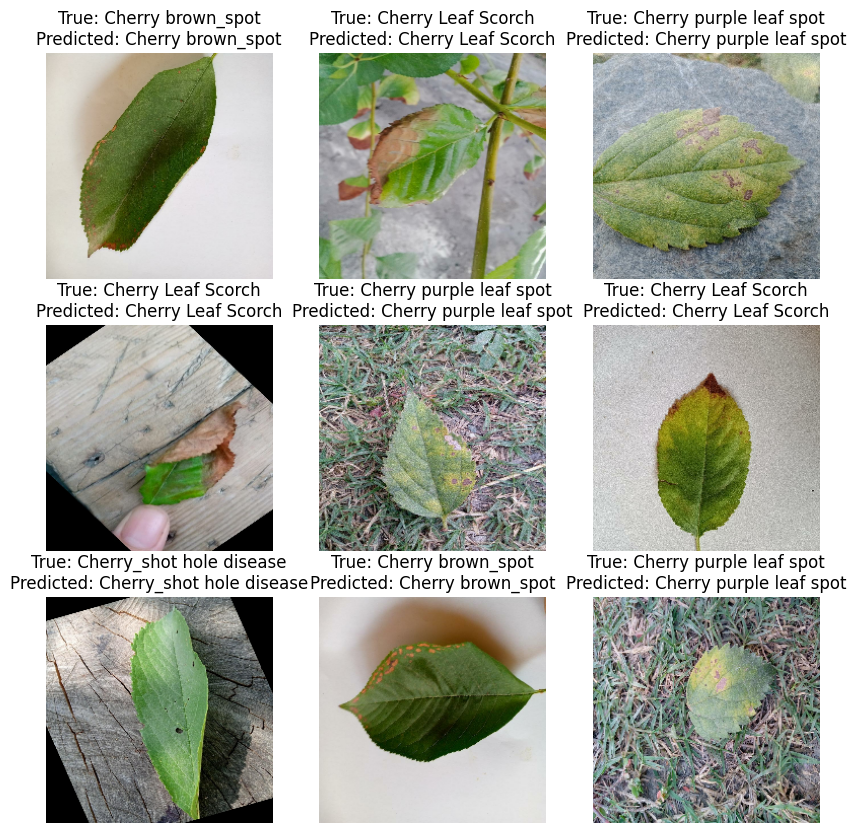

In [63]:
plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    image = images[i].numpy()
    true_label = np.argmax(labels[i].numpy())
    
    probs = resnet_model.predict(np.expand_dims(image, axis=0), verbose=0)
    pred_class = np.argmax(probs, axis=1)[0]

    plt.imshow(image.astype("uint8"))
    plt.title(f"True: {class_names[true_label]}\nPredicted: {class_names[pred_class]}")
    plt.axis("off")

plt.show()

Model ResNet menunjukkan hasil yang terbaik dibandingkan dua model sebelumnya. Model ini juga terlihat berani untuk menebak kelas minoritas, dan berhasil mendapatkan 90% kasus pada kelas minoritas, ini yang digambarkan oleh recall 0.91. Model ResNet juga memiliki AUC yang hampir sempurna, yaitu 0.9-1.0, menandakan bahwa model sangat mampu untuk membedakan antar kelas. Dari model ResNet ini juga didapat bahwa model tidak mengalami overfitting dan justru semakin konvergen pada setiap epoch

#### **D.4 Conclusion**

Dari ketiga model di atas, dan setelah melalui proses training yang panjang, dapat disimpulkan bahwa untuk menangani medical tasks image classification:
- pretrained model jauh lebih unggul dibandingkan dengan custom CNN yang dilatih dari awal. 
- Model yang dilatih dari awal sesuai dengan arsitektur AlexNet memang sudah cukup baik, tetapi model sedikit kurang berani menebak kelas minoritas. 
- Class weighting cukup efektif juga ketika terjadi class imbalance, walaupun mungkin bisa di tuning untuk mendapatkan penalty yang terbaik untuk setiap kelas
- Health Tree images mementingkan model dengan recall yang tinggi, dengan tujuan menangkap kasus positif dengan lebih akurat, dan tidak melewatkan pasien yang ternyata memiliki penyakit

Rekomendasi:
- Hyperparameter tuning untuk model custom CNN, karena berdasarkan analisis saya, model CNN yang custom dapat memiliki hasil yang akurat namun perlu menemukan parameter yang tepat, termasuk tuning class weight, learning rate, dan juga jumlah neuron di layer convolution
- Berdasarkan analisis saya, untuk menangkap pola dari kelas minoritas, perlu ditambahkan data kembali agar model bisa menangkap ciri dan juga pola pada kelas minoritas dengan lebih baik